# Modèle 1 — Régression : « elle chauffe plus que prévu »

**Membre 3 — Mobio Ivan Junior** · Étape 6 du pipeline

**Idée.** Les seuils fixes (45 °C, 60 mV) ne voient que les valeurs extrêmes. Mais une session qui atteint 40 °C un jour froid, avec un faible courant, est plus suspecte qu'une session à 42 °C en plein été avec une charge rapide.

On apprend donc ce qu'une session **devrait** atteindre compte tenu de ses conditions, puis on signale celles dont la valeur **réelle dépasse nettement la valeur prévue**.

| | |
|---|---|
| Entrées (conditions de la session) | `courant_moyen`, `soc_debut`, `temp_debut`, `mois`, `duree_min` |
| Cible A — surchauffe | `temp_max` |
| Cible B — cellule | `ecart_v_max` |
| Algorithmes | Régression linéaire (référence), Random Forest, XGBoost → **6 entraînements** |
| Évaluation | Séparation **par véhicule** : 16 véhicules d'entraînement, 4 de test jamais vus (17 à 20) |
| Vote | 1 si résidu (réel − prévu) > 99e percentile des résidus du train |

Le code réutilisable est dans `src/models/regression.py` (utilisé par `main.py`, la fusion et les tests). Ce notebook déroule chaque étape et montre les résultats.

In [1]:
# Configuration : rend le dossier src/ importable
import sys
from pathlib import Path

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import GroupKFold, cross_val_predict

from src.config import SESSIONS_PARQUET, FIGURES_DIR, TEST_VEHICLES
from src.models.regression import (FEATURES, CIBLES, PERCENTILE_VOTE, VOTES_PARQUET,
                                   algorithmes, separer, metriques, vote_sessions)

pd.set_option("display.width", 200)
pd.set_option("display.precision", 4)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

## 1. Charger les sessions de charge

Une ligne = une session de charge (étape 5, `src/sessions.py` de Kevin).

In [2]:
sessions = pd.read_parquet(SESSIONS_PARQUET)
print(f"{len(sessions):,} sessions, {sessions.vehicle_id.nunique()} véhicules")
sessions[["vehicle_id", "debut"] + FEATURES + list(CIBLES.values())].head()

30,855 sessions, 20 véhicules


,vehicle_id,debut,courant_moyen,soc_debut,temp_debut,mois,duree_min,temp_max,ecart_v_max
0,1,2019-07-26 20:02:35,-47.1911,27.2,41,7,122.9667,44,0.025
1,1,2019-07-27 04:06:56,-56.3747,30.0,39,7,100.3333,43,0.030
2,1,2019-07-28 17:25:00,-54.7752,39.6,35,7,89.2333,40,0.030
3,1,2019-07-29 11:31:06,-25.9005,26.8,36,7,188.1167,40,0.023
4,1,2019-07-29 22:20:45,-39.0839,18.8,34,7,94.7167,37,0.022


In [3]:
sessions[FEATURES + list(CIBLES.values())].describe().T

,count,mean,std,min,25%,50%,75%,max
courant_moyen,30855.0,-56.1937,11.9050,-90.3989,-65.2671,-59.5668,-45.2009,0.0000
soc_debut,30855.0,36.7218,18.9014,0.0000,22.0000,34.8000,49.6000,99.6000
temp_debut,30855.0,31.6071,5.8615,9.0000,28.0000,32.0000,36.0000,47.0000
mois,30855.0,7.2352,3.2623,1.0000,5.0000,8.0000,10.0000,12.0000
duree_min,30855.0,78.0938,56.6733,1.2000,54.7250,73.9500,93.5500,3887.6333
temp_max,30855.0,35.4134,5.4741,14.0000,32.0000,36.0000,40.0000,49.0000
ecart_v_max,30855.0,0.0400,0.0078,0.0100,0.0350,0.0410,0.0450,0.0980


## 2. Séparer par véhicule

On teste sur des véhicules **jamais vus** à l'entraînement. Si on mélangeait les sessions d'un même véhicule entre train et test, le modèle reconnaîtrait le véhicule et les résultats seraient trop optimistes.

In [4]:
train, test = separer(sessions)
print(f"Train : {len(train):,} sessions, véhicules {sorted(train.vehicle_id.unique())}")
print(f"Test  : {len(test):,} sessions, véhicules {sorted(test.vehicle_id.unique())}")

Train : 24,673 sessions, véhicules [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(14), np.int64(15), np.int64(16)]
Test  : 6,182 sessions, véhicules [np.int64(17), np.int64(18), np.int64(19), np.int64(20)]


## 3. Entraîner et comparer les 6 modèles

Pour chaque cible et chaque algorithme :

1. **Validation croisée par véhicule sur le train** (`GroupKFold`, 4 plis) : chaque session reçoit une prédiction faite par un modèle qui n'a jamais vu son véhicule. Ces prédictions « hors-échantillon » servent à **choisir le meilleur algorithme** et à **fixer le seuil de vote**.
2. Entraînement sur tout le train, puis **mesure finale sur le test**.

On ne choisit jamais le modèle sur le test : sinon, le test ne serait plus une mesure honnête.

In [5]:
plis = GroupKFold(n_splits=4)
lignes, oof, modeles_entraines, predictions_test = [], {}, {}, {}

for anomalie, cible in CIBLES.items():
    for nom, modele in algorithmes().items():
        prevu_oof = cross_val_predict(modele, train[FEATURES], train[cible],
                                      groups=train["vehicle_id"], cv=plis)
        modele.fit(train[FEATURES], train[cible])
        prevu_test = modele.predict(test[FEATURES])

        oof[(cible, nom)] = prevu_oof
        modeles_entraines[(cible, nom)] = modele
        predictions_test[(cible, nom)] = prevu_test
        m_cv, m_test = metriques(train[cible], prevu_oof), metriques(test[cible], prevu_test)
        lignes.append({"cible": cible, "algorithme": nom,
                       "MAE cv": m_cv["mae"], "MAE test": m_test["mae"],
                       "RMSE test": m_test["rmse"], "R² test": m_test["r2"]})
        print(f"{cible:<12} {nom:<14} terminé")

resultats = pd.DataFrame(lignes)
resultats["meilleur"] = resultats.groupby("cible")["MAE cv"].transform("min") == resultats["MAE cv"]
resultats

temp_max     lineaire       terminé


temp_max     random_forest  terminé


temp_max     xgboost        terminé
ecart_v_max  lineaire       terminé


ecart_v_max  random_forest  terminé


ecart_v_max  xgboost        terminé


,cible,algorithme,MAE cv,MAE test,RMSE test,R² test,meilleur
0,temp_max,lineaire,0.7278,0.7334,1.0509,0.9628,False
1,temp_max,random_forest,0.5611,0.5617,0.7650,0.9803,False
2,temp_max,xgboost,0.5163,0.5233,0.6959,0.9837,True
3,ecart_v_max,lineaire,0.0050,0.0052,0.0067,0.2288,False
4,ecart_v_max,random_forest,0.0049,0.0049,0.0063,0.3074,False
5,ecart_v_max,xgboost,0.0048,0.0049,0.0064,0.2991,True


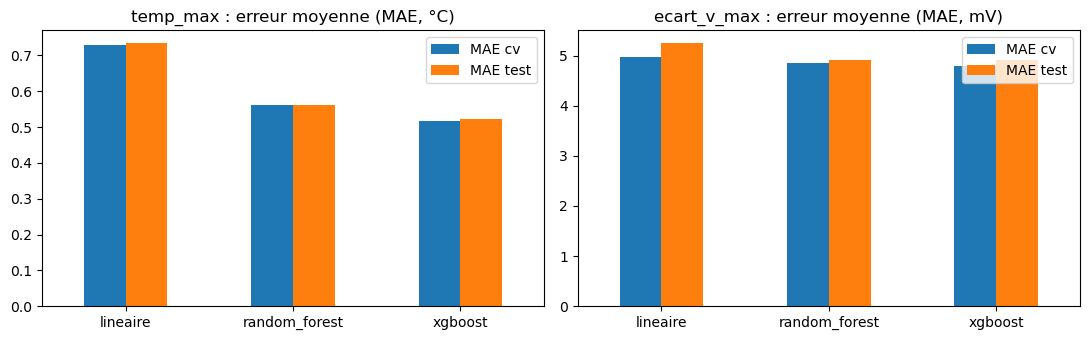

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for ax, (anomalie, cible) in zip(axes, CIBLES.items()):
    r = resultats[resultats.cible == cible].set_index("algorithme")
    unite, facteur = ("°C", 1) if cible == "temp_max" else ("mV", 1000)
    (r[["MAE cv", "MAE test"]] * facteur).plot.bar(ax=ax, rot=0)
    ax.set_title(f"{cible} : erreur moyenne (MAE, {unite})")
    ax.set_xlabel("")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "regression_comparaison_mae.png", dpi=120)
plt.show()

**Lecture.** La MAE en validation croisée et la MAE sur le test sont très proches : le modèle se généralise bien à des véhicules qu'il n'a jamais vus. XGBoost est le meilleur pour les deux cibles.

## 4. Prévu contre réel (meilleur modèle, véhicules de test)

Meilleur modèle par cible : {'temp_max': 'xgboost', 'ecart_v_max': 'xgboost'}


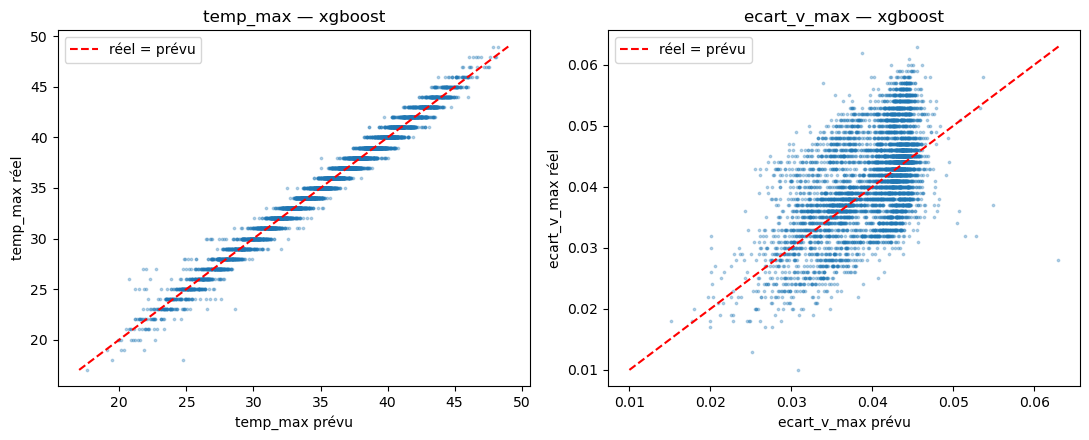

In [7]:
meilleurs = resultats[resultats.meilleur].set_index("cible")["algorithme"].to_dict()
print("Meilleur modèle par cible :", meilleurs)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, cible in zip(axes, CIBLES.values()):
    prevu = predictions_test[(cible, meilleurs[cible])]
    ax.scatter(prevu, test[cible], s=3, alpha=0.3)
    bornes = [min(prevu.min(), test[cible].min()), max(prevu.max(), test[cible].max())]
    ax.plot(bornes, bornes, "r--", label="réel = prévu")
    ax.set_xlabel(f"{cible} prévu")
    ax.set_ylabel(f"{cible} réel")
    ax.set_title(f"{cible} — {meilleurs[cible]}")
    ax.legend()
plt.tight_layout()
plt.savefig(FIGURES_DIR / "regression_prevu_vs_reel.png", dpi=120)
plt.show()

**Lecture.**
- **`temp_max`** : les points suivent la diagonale. On prédit la température maximale d'une session à environ 0,5 °C près.
- **`ecart_v_max`** : le nuage est large (R² ≈ 0,3). Les conditions de charge expliquent mal l'écart de tension : il dépend surtout de **l'état de la batterie elle-même**. C'est un résultat en soi, et c'est justement ce qui rend un écart anormal intéressant.

## 5. Fixer le seuil de vote

Le **résidu** est réel − prévu. Un résidu positif et grand veut dire « plus chaud (ou plus déséquilibré) que prévu ».

Le seuil est le **99e percentile des résidus hors-échantillon** du train. On n'utilise pas les résidus du modèle sur ses propres données d'entraînement : une forêt « connaît » ces réponses, et ses résidus y seraient trop petits.

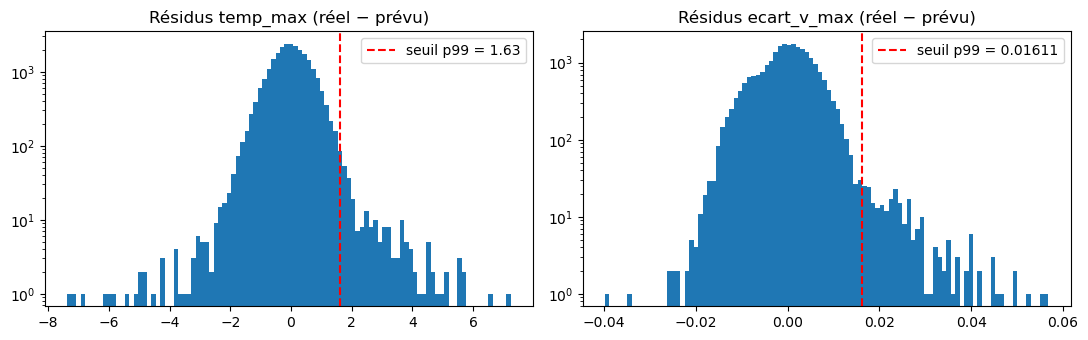

Seuils de vote : {'surchauffe': 1.6301, 'cellule': 0.0161}


In [8]:
seuils = {}
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for ax, (anomalie, cible) in zip(axes, CIBLES.items()):
    residus = train[cible] - oof[(cible, meilleurs[cible])]
    seuils[anomalie] = float(np.percentile(residus, PERCENTILE_VOTE))
    ax.hist(residus, bins=100)
    ax.axvline(seuils[anomalie], color="r", linestyle="--",
               label=f"seuil p{PERCENTILE_VOTE} = {seuils[anomalie]:.4g}")
    ax.set_yscale("log")
    ax.set_title(f"Résidus {cible} (réel − prévu)")
    ax.legend()
plt.tight_layout()
plt.savefig(FIGURES_DIR / "regression_residus.png", dpi=120)
plt.show()
print("Seuils de vote :", {a: round(s, 4) for a, s in seuils.items()})

## 6. Votes sur toutes les sessions

In [9]:
modeles = {a: modeles_entraines[(c, meilleurs[c])] for a, c in CIBLES.items()}
votes = vote_sessions(sessions, modeles, seuils)
est_test = votes.vehicle_id.isin(TEST_VEHICLES)
for a in CIBLES:
    col = f"vote_regression_{a}"
    print(f"{col:<28} train {votes.loc[~est_test, col].mean():.2%} | test {votes.loc[est_test, col].mean():.2%}")

vote_regression_surchauffe   train 0.65% | test 1.07%
vote_regression_cellule      train 0.73% | test 0.39%


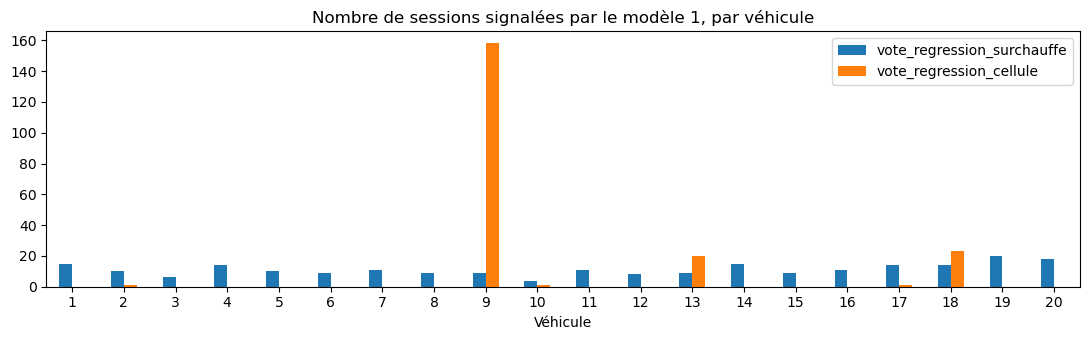

vehicle_id,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20
vote_regression_surchauffe,15,10,6,14,10,9,11,9,9,4,11,8,9,15,9,11,14,14,20,18
vote_regression_cellule,0,1,0,0,0,0,0,0,158,1,0,0,20,0,0,0,1,23,0,0


In [10]:
par_vehicule = votes.groupby("vehicle_id")[["vote_regression_surchauffe", "vote_regression_cellule"]].sum()
ax = par_vehicule.plot.bar(figsize=(11, 3.5), rot=0)
ax.set_title("Nombre de sessions signalées par le modèle 1, par véhicule")
ax.set_xlabel("Véhicule")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "regression_votes_par_vehicule.png", dpi=120)
plt.show()
par_vehicule.T

**Lecture.**
- **Surchauffe** : les votes sont répartis sur tous les véhicules. Ce sont des sessions ponctuellement plus chaudes que prévu, pas un véhicule défectueux.
- **Cellule** : les votes se concentrent sur le **véhicule 9**, puis les véhicules 18 et 13. Ce sont les mêmes que ceux trouvés par le seuil de 60 mV : **deux approches indépendantes désignent le même véhicule**.

## 7. Exemples : les sessions les plus « plus chaudes que prévu »

In [11]:
exemples = (votes.merge(sessions[["session_id", "debut", "courant_moyen", "temp_debut", "temp_max"]], on="session_id")
              .sort_values("residu_temp_max", ascending=False)
              .head(10))
exemples[["vehicle_id", "debut", "courant_moyen", "temp_debut", "temp_max", "temp_max_prevu", "residu_temp_max"]].round(2)

,vehicle_id,debut,courant_moyen,temp_debut,temp_max,temp_max_prevu,residu_temp_max
27140,18,2020-12-17 06:39:20,-51.23,17,26,20.70,5.30
24082,16,2021-01-08 07:06:47,-47.42,18,28,22.74,5.26
28711,19,2021-01-09 11:47:10,-66.26,19,27,21.76,5.24
30314,20,2021-01-12 03:21:18,-68.91,19,27,21.96,5.04
5823,4,2021-01-09 07:01:31,-39.83,18,27,22.18,4.82
18034,12,2020-12-17 02:36:08,-51.77,18,29,24.49,4.51
27189,18,2021-01-11 11:35:56,-45.03,11,27,22.76,4.24
13655,9,2021-01-08 01:19:52,-64.42,19,27,22.85,4.15
18106,12,2021-01-19 07:00:19,-57.78,18,29,24.87,4.13
5775,4,2020-12-15 11:51:43,-47.05,17,26,22.06,3.94


## 8. Importance des variables

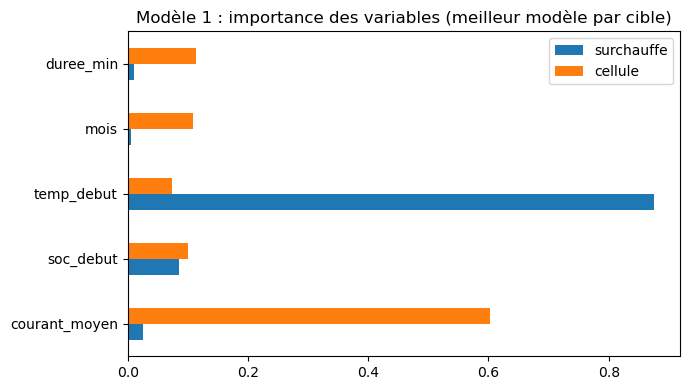

,surchauffe,cellule
courant_moyen,0.025,0.602
soc_debut,0.085,0.101
temp_debut,0.875,0.074
mois,0.005,0.109
duree_min,0.010,0.114


In [12]:
importance = pd.DataFrame({a: m.feature_importances_ for a, m in modeles.items()}, index=FEATURES)
ax = importance.plot.barh(figsize=(7, 4))
ax.set_title("Modèle 1 : importance des variables (meilleur modèle par cible)")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "regression_importance.png", dpi=120)
plt.show()
importance.round(3)

**Lecture.**
- **Surchauffe** : la **température de départ** domine. Une batterie qui commence chaude finit chaude ; le modèle apprend la montée normale et signale ce qui dépasse.
- **Cellule** : le **courant** est la variable principale : un courant de charge plus fort creuse l'écart entre cellules.

## 9. Sauvegarder les votes pour la fusion

Fichier lu par Mohamed (fusion par vote) : une colonne par anomalie (`vote_regression_surchauffe`, `vote_regression_cellule`) et `vote_regression` (l'un ou l'autre).

In [13]:
votes.to_parquet(VOTES_PARQUET, index=False)
print("Votes enregistrés :", VOTES_PARQUET)
votes.head()

Votes enregistrés : C:\Users\hp\Documents\HESTIM 2\PROJET PISTE\battery-charging-data-of-on-road-electric-vehicles-main\Dataset_automobile\data\processed\votes_regression.parquet


,vehicle_id,session_id,temp_max_prevu,residu_temp_max,vote_regression_surchauffe,ecart_v_max_prevu,residu_ecart_v_max,vote_regression_cellule,vote_regression
0,1,1,43.7570,0.2430,0,0.0359,-0.0109,0,0
1,1,2,43.0227,-0.0227,0,0.0372,-0.0072,0,0
2,1,3,38.3964,1.6036,0,0.0380,-0.0080,0,0
3,1,4,38.0990,1.9010,1,0.0278,-0.0048,0,1
4,1,5,37.3225,-0.3225,0,0.0306,-0.0086,0,0


## 10. Conclusions

| | Surchauffe (`temp_max`) | Cellule (`ecart_v_max`) |
|---|---|---|
| Meilleur modèle | XGBoost | XGBoost |
| Précision (test) | MAE ≈ 0,5 °C, R² ≈ 0,98 | MAE ≈ 5 mV, R² ≈ 0,3 |
| Vote | ≈ 1 % des sessions | ≈ 0,5 % des sessions |
| Ce qu'on apprend | Les conditions expliquent presque toute la température : un écart au prévu est un vrai signal | Les conditions expliquent mal l'écart de tension : il vient de l'état de la batterie |
| Véhicules signalés | Répartis sur toute la flotte | Surtout le **véhicule 9** (puis 18 et 13) |

**Limites.**
- La température est enregistrée au degré près : une erreur de 0,5 °C est proche de la précision du capteur.
- Le seuil (99e percentile) signale par construction environ 1 % des sessions : c'est un choix, à discuter avec la fusion par vote.
- `duree_min` n'est connue qu'à la fin de la session : ce modèle analyse une session terminée. L'anticipation est le rôle du modèle 2.